# 06 · What drives the forecast

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/06_explainability.ipynb)

Companion notebook for *Chronos-2 in Practice (3/7)*.

**What you will learn**

- Four model-agnostic ways to ask what a forecast is using, in increasing order of cost:
  ablation, permutation, exact Shapley values and occlusion.
- Which of the covariates from notebook `05_covariates` the model relies on, how sure that
  answer is after a full year of windows, and why ablation and Shapley can disagree.
- Which part of the past matters, using the context segments of Hertel et al. (2026).
- A what-if: move a known-future covariate and watch the forecast move with it.

Runtime: ~25 min on a GPU (FAST_MODE: ~2 min).

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time
from dataclasses import replace

import numpy as np
import pandas as pd
from huggingface_hub.utils import logging as hub_logging
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.config import SEED, get_device, get_paths, is_fast_mode, set_seed
from c2p.data import (
    CALENDAR_COLUMNS,
    add_calendar_features,
    spain_energy_frame,
    validate_and_prepare,
)
from c2p.eval import iter_windows
from c2p.experiments import DAY_AHEAD_BLOCK, FREQ, PRICE, TSO_COVARIATES, day_ahead_config
from c2p.explain import (
    IMPORTANCE_COL,
    PLAYER_COL,
    SHAPLEY_COL,
    ablation_importance,
    context_segments,
    covariate_shapley,
    importance_summary,
    occlusion,
    permutation_importance,
    stack_windows,
    temporal_shapley,
)
from c2p.models import Chronos2Forecaster, load_chronos2
from c2p.plots.evaluation import plot_interval_bars, plot_what_if
from c2p.plotting import (
    plot_benchmarks,
    plot_metric_vs_param,
    save_figure,
    set_style,
)
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
hub_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cpu
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-26 05:45
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 4
                 gpu: none
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. Chronos-2 ships no explainer, and that is fine

There is no `.explain()`, no feature-importance attribute, no built-in attribution. What there
is instead is the thing every attribution method needs: a cheap way to re-run the model
with part of its input removed. Zero-shot inference costs one forward pass, so switching an input
off and measuring the damage is affordable in a way it never is for a model you had to train.

Every technique below is **model-agnostic**: none of them looks inside the network. That is a
choice, not a limitation to apologise for. Attention weights are tempting (the group
attention layer is right there), but a decade of work on attention as explanation (Jain &
Wallace, 2019) says attention weights are not a faithful account of what a model used, and
Chronos-2's group attention has had no such validation at all. Inputs you can switch off give
answers you can check.

The four methods, in increasing order of cost and fidelity:

| Method | Cost | What it tells you | What it misses |
| --- | --- | --- | --- |
| **Ablation** | `n + 1` forecasts | What drops when one covariate is removed | Interactions: two redundant covariates both look useless |
| **Permutation** | `n x repeats` | What drops when one covariate is scrambled | Same, plus it feeds the model impossible inputs |
| **Shapley** | `2**n` forecasts | Each player's average marginal contribution over all coalitions | Nothing in principle; affordable only for a handful of players |
| **Occlusion** | one per position | Which *part of the past* matters | Attribution to inputs, not to mechanism |

Shapley values are exact here, not sampled: the trick that makes them affordable is grouping the
inputs into a few meaningful players rather than approximating the average.

In [3]:
COLUMNS = [ID_COL, TIMESTAMP_COL, PRICE, *TSO_COVARIATES]
price, report = validate_and_prepare(spain_energy_frame()[COLUMNS], freq=FREQ, target=PRICE)
price = add_calendar_features(price)
CALENDAR = tuple(CALENDAR_COLUMNS)
KNOWN = (*CALENDAR, *TSO_COVARIATES)

# The players: calendar as one group, each operator forecast on its own.
PLAYERS = {
    "calendar": CALENDAR,
    "load forecast": ("load_forecast_tso",),
    "solar forecast": ("solar_forecast_tso",),
    "wind forecast": ("wind_onshore_forecast_tso",),
}
print("Players:", {name: len(columns) for name, columns in PLAYERS.items()})

Players: {'calendar': 5, 'load forecast': 1, 'solar forecast': 1, 'wind forecast': 1}


Explaining one window would explain one day. Instead the 365 day-ahead windows of the 2018
test year, the same ones that notebook `05` scored, are *stacked*: each window's series
becomes its own series, so one `predict` call covers them all and every number below is an
average over a full year of days. A dozen windows is not enough here: the covariates remove a
few thousandths of WQL, and that is smaller than the difference between one day and the next.

An attribution is computed per window and the windows disagree, so every table below carries
the mean over windows **with a 95% bootstrap interval** (`importance_summary`, resampling
blocks of seven consecutive days as everywhere else in the series). A player whose interval
contains zero has not been shown to matter; two players whose intervals overlap have not been
ranked.

In [4]:
CONFIG = day_ahead_config(FAST_MODE, target=PRICE, known_covariates=KNOWN, max_context=2048)
if FAST_MODE:
    CONFIG = replace(CONFIG, n_windows=3)
N_WINDOWS = CONFIG.n_windows
# Consecutive days are resampled in blocks; the three windows of fast mode are a month apart.
BLOCK = 1 if FAST_MODE else DAY_AHEAD_BLOCK
windows = list(iter_windows(price, CONFIG))
context, future, actuals = stack_windows(windows)
print(
    f"{len(windows)} windows stacked into {context[ID_COL].nunique()} series, "
    f"{len(context):,} context rows, {len(future):,} future rows"
)
print(f"Cutoffs: {windows[0].cutoff} to {windows[-1].cutoff}")

pipeline = load_chronos2(device=DEVICE)
chronos = Chronos2Forecaster(pipeline)

365 windows stacked into 365 series, 747,520 context rows, 8,760 future rows
Cutoffs: 2017-12-31 22:00:00 to 2018-12-30 22:00:00


## 2. The cheap questions: ablation and permutation

Both score the same way here: the increase in WQL when a covariate is switched off, so a positive
number means the covariate was helping.

In [5]:
start = time.perf_counter()
shared = {
    "covariates": PLAYERS,
    "prediction_length": CONFIG.prediction_length,
    "freq": FREQ,
    "target": PRICE,
    "actuals": actuals,
}
ablation = ablation_importance(chronos, context, future, **shared).assign(method="Ablation")
permutation = permutation_importance(
    chronos, context, future, n_repeats=2 if FAST_MODE else 5, **shared
).assign(method="Permutation")
cheap = pd.concat([ablation, permutation], ignore_index=True)
print(f"Ablation + permutation in {time.perf_counter() - start:.0f} s")
print("Saved", save_results(cheap, "06_covariate_importance", PATHS).name)

Ablation + permutation in 450 s
Saved 06_covariate_importance.csv


Saved 06_covariate_importance_summary.csv
        player      method     mean   ci_low  ci_high  share_positive  n_windows
      calendar    Ablation -0.00269 -0.00567 -0.00045         0.42466        365
 load forecast    Ablation  0.00091 -0.00024  0.00224         0.56712        365
solar forecast    Ablation -0.00026 -0.00084  0.00024         0.52329        365
 wind forecast    Ablation  0.00337  0.00122  0.00571         0.66575        365
      calendar Permutation  0.00344  0.00076  0.00604         0.68493        365
 load forecast Permutation  0.00050 -0.00073  0.00177         0.59178        365
solar forecast Permutation -0.00050 -0.00102  0.00002         0.50137        365
 wind forecast Permutation  0.00291  0.00019  0.00546         0.65479        365


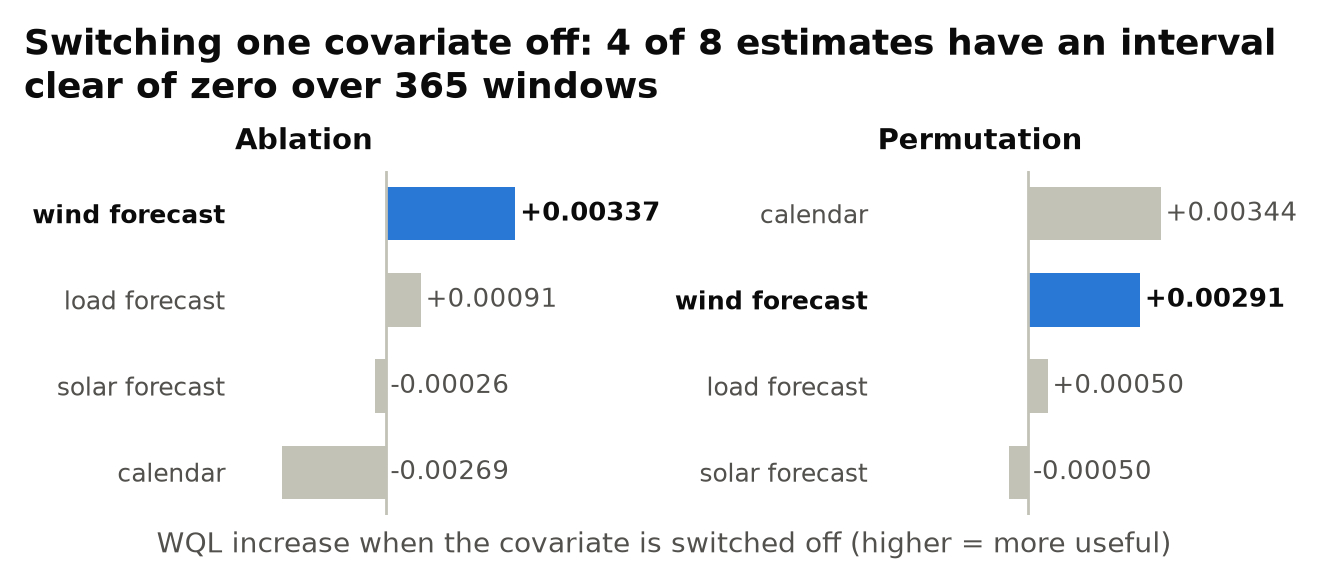

In [6]:
cheap = load_results("06_covariate_importance", PATHS)
summary = (
    cheap.groupby([PLAYER_COL, "method"], as_index=False)[IMPORTANCE_COL]
    .mean()
    .rename(columns={PLAYER_COL: "model", "method": "benchmark"})
)
importance = importance_summary(
    cheap, value=IMPORTANCE_COL, by=(PLAYER_COL, "method"), block_length=BLOCK
)
print("Saved", save_results(importance, "06_covariate_importance_summary", PATHS).name)
clear = importance[(importance["ci_low"] > 0) | (importance["ci_high"] < 0)]
top = summary[summary["benchmark"] == "Ablation"].sort_values(IMPORTANCE_COL, ascending=False)
title = (
    f"Switching one covariate off: {len(clear)} of {len(importance)} estimates "
    f"have an interval clear of zero over {N_WINDOWS} windows"
)
fig = plot_benchmarks(
    summary,
    value=IMPORTANCE_COL,
    highlight=str(top.iloc[0]["model"]),
    xlabel="WQL increase when the covariate is switched off (higher = more useful)",
    title=title,
    value_format="{:+.5f}",
)
(figure_path,) = save_figure(fig, "06_covariate_importance", PATHS.figures)
display(Image(filename=figure_path, width=800))
print(importance.round(5).to_string(index=False))

## 3. The fair question: exact Shapley values

Ablation asks "what happens without this covariate, when all the others are present". That is one
coalition out of sixteen, and it is the one most likely to understate a covariate that another can
substitute for. Shapley values average each player's marginal contribution over *every* subset of
the others, which is the only way redundancy and complementarity show up.

With four players that is 16 forecasts, and because coalitions share work, far fewer than 16
separate calls.

In [7]:
start = time.perf_counter()
explanation = covariate_shapley(
    chronos,
    context,
    future,
    covariates=PLAYERS,
    prediction_length=CONFIG.prediction_length,
    freq=FREQ,
    target=PRICE,
    value="wql_reduction",
    actuals=actuals,
)
print(
    f"{len(explanation.players)} players -> {explanation.n_forecasts} coalition forecasts "
    f"in {explanation.n_calls} calls, {explanation.seconds:.0f} s"
)
print("Saved", save_results(explanation.shapley, "06_covariate_shapley", PATHS).name)

4 players -> 5840 coalition forecasts in 16 calls, 150 s
Saved 06_covariate_shapley.csv


Saved 06_covariate_shapley_summary.csv
        player     mean   ci_low  ci_high  share_positive  n_windows
      calendar -0.00137 -0.00349  0.00024         0.45753        365
 load forecast  0.00105 -0.00035  0.00279         0.53973        365
solar forecast -0.00029 -0.00083  0.00022         0.47671        365
 wind forecast  0.00383  0.00154  0.00654         0.65753        365
      all four  0.00322  0.00007  0.00666         0.63836        365


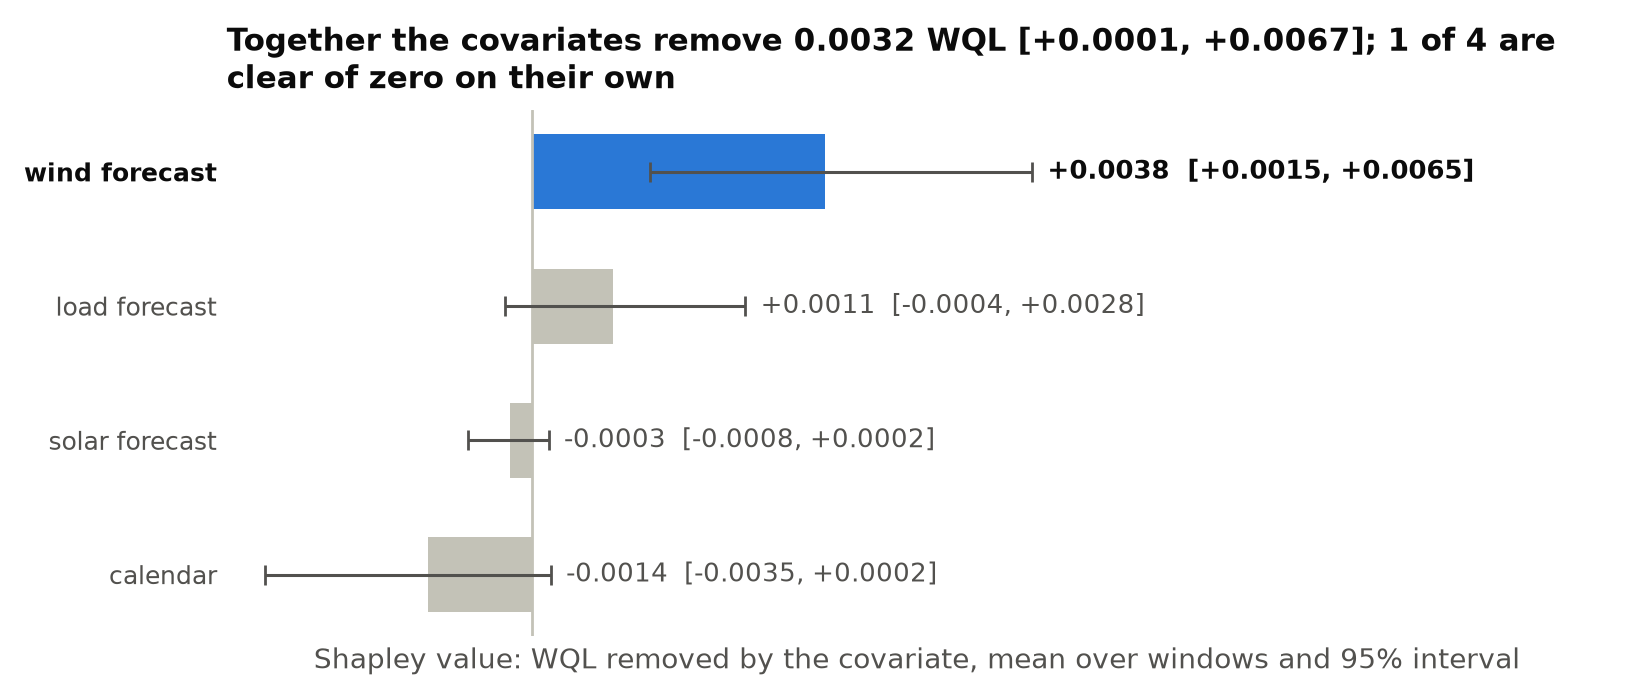

In [8]:
shapley = load_results("06_covariate_shapley", PATHS)
# The players' values add up, window by window, to what all the covariates remove together.
total = (
    shapley.groupby(ID_COL, as_index=False)[SHAPLEY_COL].sum().assign(**{PLAYER_COL: "all four"})
)
shapley_summary = importance_summary(
    pd.concat([shapley, total], ignore_index=True), value=SHAPLEY_COL, block_length=BLOCK
)
print("Saved", save_results(shapley_summary, "06_covariate_shapley_summary", PATHS).name)

shapley_summary = load_results("06_covariate_shapley_summary", PATHS)
players = shapley_summary[shapley_summary[PLAYER_COL] != "all four"]
together = shapley_summary.set_index(PLAYER_COL).loc["all four"]
clear = players[(players["ci_low"] > 0) | (players["ci_high"] < 0)]
title = (
    f"Together the covariates remove {together['mean']:.4f} WQL "
    f"[{together['ci_low']:+.4f}, {together['ci_high']:+.4f}]; "
    f"{len(clear)} of {len(players)} are clear of zero on their own"
)
ax = plot_interval_bars(
    players,
    label=PLAYER_COL,
    highlight=str(players.sort_values("mean").iloc[-1][PLAYER_COL]),
    title=title,
    xlabel="Shapley value: WQL removed by the covariate, mean over windows and 95% interval",
)
(figure_path,) = save_figure(ax.figure, "06_covariate_shapley", PATHS.figures)
display(Image(filename=figure_path, width=800))
print(shapley_summary.round(5).to_string(index=False))

## 4. Which part of the past?

The same machinery applies to the target's own history. Following Hertel et al. (2026), the
context is cut into four segments (the last day, the rest of the week, the rest of four weeks and
everything older), and each is a player that a coalition can switch off by setting those target
values to NaN.

This answers a question the context sweep of notebook `03` could only answer in aggregate: not
"how much history helps" but *which* history.

In [9]:
SEGMENTS = context_segments((24, 168, 672))
print("Segments:", [segment.name for segment in SEGMENTS])

temporal = temporal_shapley(
    chronos,
    context,
    future,
    segments=(24, 168, 672),
    prediction_length=CONFIG.prediction_length,
    freq=FREQ,
    target=PRICE,
    value="wql_reduction",
    actuals=actuals,
)
print(
    f"{len(temporal.players)} players -> {temporal.n_forecasts} coalition forecasts "
    f"in {temporal.n_calls} calls, {temporal.seconds:.0f} s"
)
print("Saved", save_results(temporal.shapley, "06_context_shapley", PATHS).name)

Segments: ['lags 1-24', 'lags 25-168', 'lags 169-672', 'lags 673+']
4 players -> 5840 coalition forecasts in 1 calls, 3134 s
Saved 06_context_shapley.csv


Saved 06_context_shapley_summary.csv
       player    mean  ci_low  ci_high  share_positive  n_windows
    lags 1-24 0.04324 0.03086  0.05943         0.94795        365
  lags 25-168 0.02897 0.02248  0.03671         0.93151        365
 lags 169-672 0.02329 0.01950  0.02760         0.91781        365
    lags 673+ 0.01295 0.00870  0.01760         0.80000        365
whole context 0.10844 0.08748  0.13650         0.99178        365


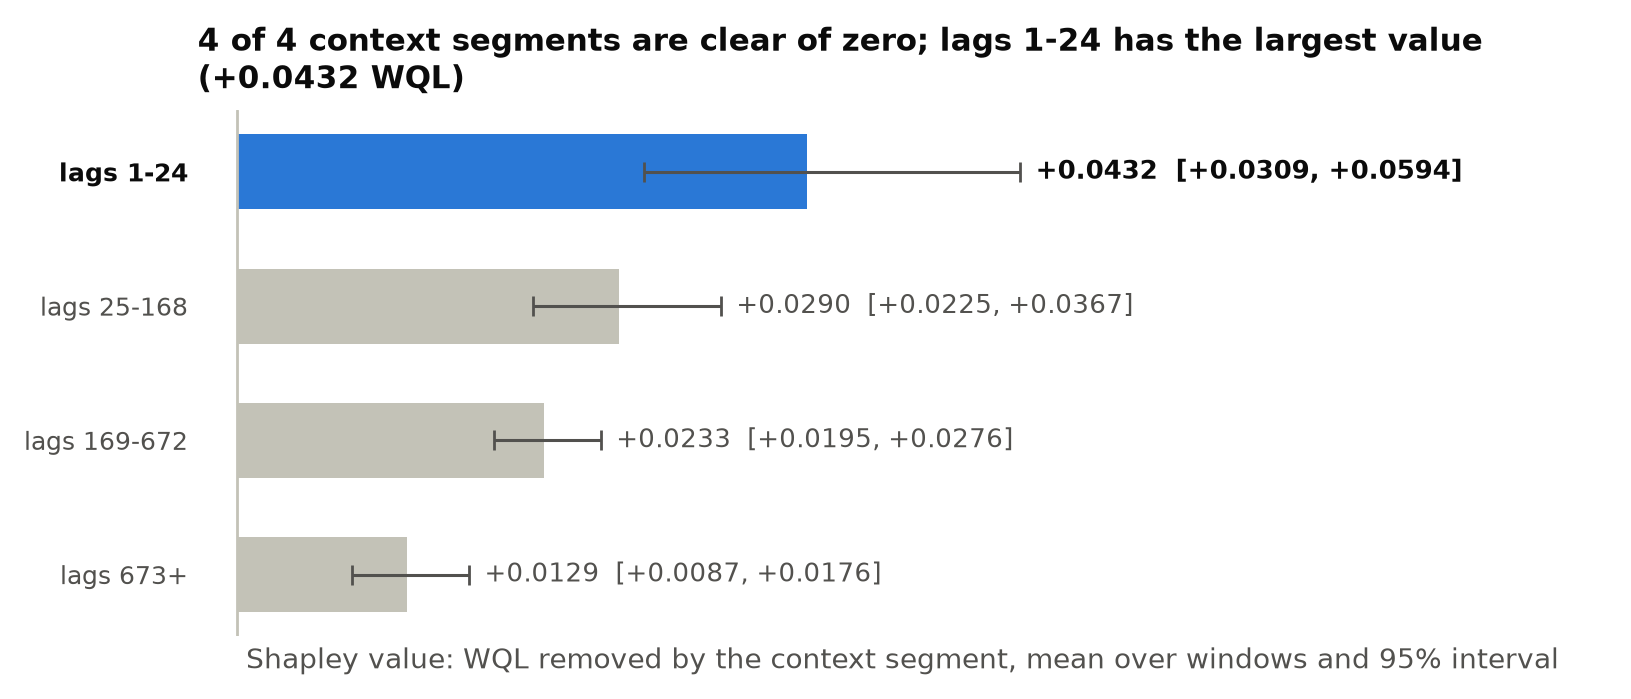

In [10]:
context_shapley = load_results("06_context_shapley", PATHS)
total = (
    context_shapley.groupby(ID_COL, as_index=False)[SHAPLEY_COL]
    .sum()
    .assign(**{PLAYER_COL: "whole context"})
)
context_summary = importance_summary(
    pd.concat([context_shapley, total], ignore_index=True), value=SHAPLEY_COL, block_length=BLOCK
)
print("Saved", save_results(context_summary, "06_context_shapley_summary", PATHS).name)

context_summary = load_results("06_context_shapley_summary", PATHS)
segments = context_summary[context_summary[PLAYER_COL] != "whole context"]
whole = context_summary.set_index(PLAYER_COL).loc["whole context"]
clear = segments[segments["ci_low"] > 0]
best = segments.sort_values("mean").iloc[-1]
title = (
    f"{len(clear)} of {len(segments)} context segments are clear of zero; "
    f"{best[PLAYER_COL]} has the largest value ({best['mean']:+.4f} WQL)"
)
ax = plot_interval_bars(
    segments,
    label=PLAYER_COL,
    highlight=str(best[PLAYER_COL]),
    title=title,
    xlabel="Shapley value: WQL removed by the context segment, mean over windows and 95% interval",
)
(figure_path,) = save_figure(ax.figure, "06_context_shapley", PATHS.figures)
display(Image(filename=figure_path, width=800))
print(context_summary.round(5).to_string(index=False))

How do the two scales compare? The whole context against all four covariates, window by
window. The ratio of the two means is a ratio of a large number to a small noisy one, so it
gets its own interval: the windows are resampled together, in the same blocks of seven days,
and the ratio is recomputed.

In [11]:
covariates_by_window = (
    load_results("06_covariate_shapley", PATHS).groupby(ID_COL)[SHAPLEY_COL].sum().sort_index()
)
context_by_window = (
    load_results("06_context_shapley", PATHS).groupby(ID_COL)[SHAPLEY_COL].sum().sort_index()
)
assert covariates_by_window.index.equals(context_by_window.index)
rng = np.random.default_rng(SEED)
n = len(context_by_window)
# The same block resampling as the tables above, applied to both columns at once.
starts = rng.integers(0, n, size=(2000, -(-n // BLOCK)))
draws = ((starts[:, :, None] + np.arange(BLOCK)) % n).reshape(2000, -1)[:, :n]
context_means = context_by_window.to_numpy()[draws].mean(axis=1)
covariate_means = covariates_by_window.to_numpy()[draws].mean(axis=1)
ratios = context_means / covariate_means
scales = pd.DataFrame(
    {
        "context_wql_removed": [context_by_window.mean()],
        "covariates_wql_removed": [covariates_by_window.mean()],
        "ratio": [context_by_window.mean() / covariates_by_window.mean()],
        "ratio_ci_low": [np.quantile(ratios, 0.025)],
        "ratio_ci_high": [np.quantile(ratios, 0.975)],
        "share_resamples_covariates_positive": [(covariate_means > 0).mean()],
        "n_windows": [len(context_by_window)],
    }
)
print("Saved", save_results(scales, "06_context_vs_covariates", PATHS).name)
print(scales.round(4).T.to_string(header=False))

Saved 06_context_vs_covariates.csv
context_wql_removed                    0.1084
covariates_wql_removed                 0.0032
ratio                                 33.6407
ratio_ci_low                          15.0914
ratio_ci_high                        177.6187
share_resamples_covariates_positive    0.9800
n_windows                            365.0000


Occlusion asks the same thing at finer resolution and far lower cost: slide a one-day NaN window
back through the context and record the damage at each position. It cannot attribute (every
position is scored with all the others present), but it shows the shape.

In [12]:
occluded = occlusion(
    chronos,
    context,
    future,
    window=24,
    stride=24,
    max_lag=168 if FAST_MODE else 672,
    prediction_length=CONFIG.prediction_length,
    freq=FREQ,
    target=PRICE,
    actuals=actuals,
)
print("Saved", save_results(occluded, "06_occlusion", PATHS).name)

Saved 06_occlusion.csv


Saved 06_occlusion_summary.csv
Day 1 before the cutoff: +0.0209 [+0.0121, +0.0325]; largest of the other 27 days: +0.0009


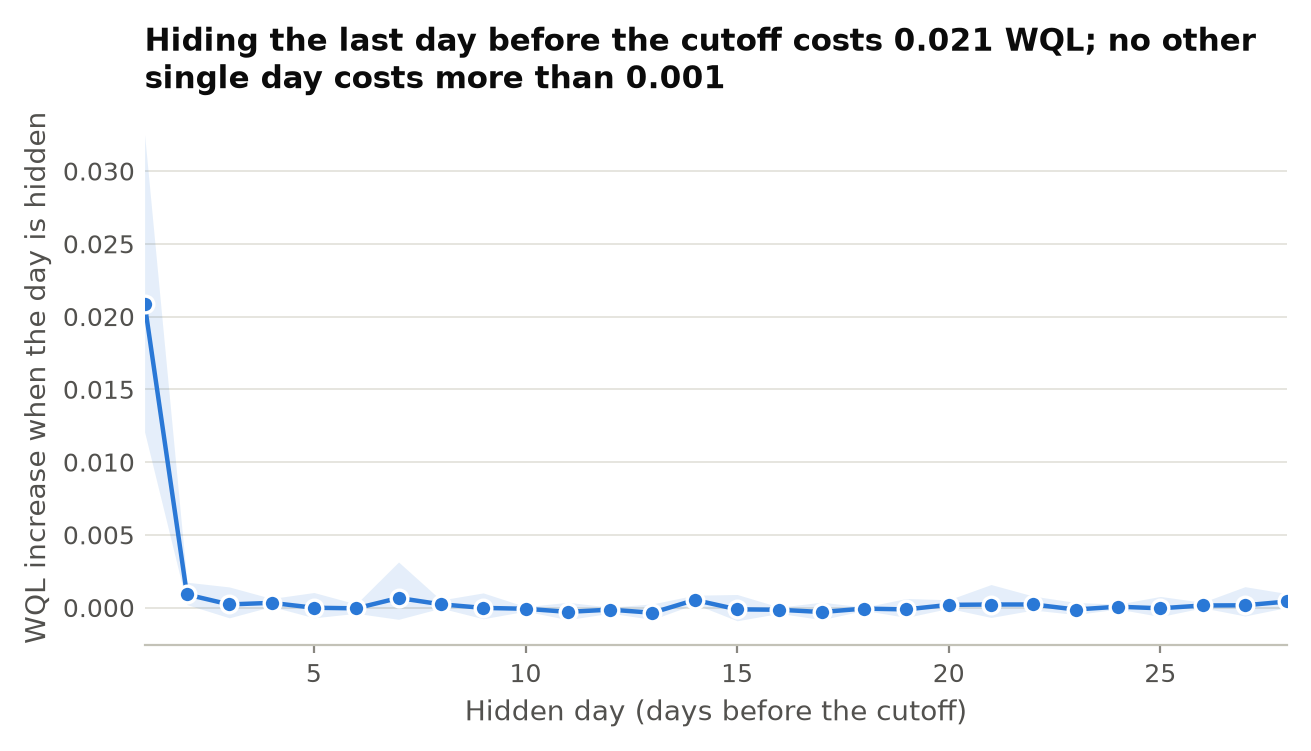

In [13]:
occluded = load_results("06_occlusion", PATHS)
occlusion_summary = importance_summary(
    occluded, value=IMPORTANCE_COL, by=("first_lag",), block_length=BLOCK
)
print("Saved", save_results(occlusion_summary, "06_occlusion_summary", PATHS).name)

# One point per hidden day: lags 1-24 are day 1 before the cutoff, lags 25-48 day 2, ...
by_day = occlusion_summary.assign(
    days_back=(occlusion_summary["first_lag"] - 1) // 24 + 1, part="One day hidden"
)
worst = by_day.sort_values("mean", ascending=False).iloc[0]
rest = by_day.loc[by_day["days_back"] != worst["days_back"], "mean"].max()
print(
    f"Day {int(worst['days_back'])} before the cutoff: {worst['mean']:+.4f} "
    f"[{worst['ci_low']:+.4f}, {worst['ci_high']:+.4f}]; largest of the other "
    f"{len(by_day) - 1} days: {rest:+.4f}"
)
ax = plot_metric_vs_param(
    by_day,
    x="days_back",
    y="mean",
    hue="part",
    band=("ci_low", "ci_high"),
    colors={},
    title=(
        f"Hiding the last day before the cutoff costs {worst['mean']:.3f} WQL; "
        f"no other single day costs more than {rest:.3f}"
    ),
    xlabel="Hidden day (days before the cutoff)",
    ylabel="WQL increase when the day is hidden",
)
(figure_path,) = save_figure(ax.figure, "06_occlusion", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 5. What-if: move a covariate and watch

Attribution says what mattered on average. A what-if says what *this* forecast would have been
under a different input, which is usually the question a planner is really asking. Because the
operator's wind forecast is a known-future covariate, changing it is a one-line intervention.

This is a sensitivity analysis, not a causal claim: it shows how the model responds, which is
useful because it is checkable against domain knowledge. More wind in the Spanish
market should push the price *down*.

In [14]:
ONE = sorted(context[ID_COL].unique())[-1]  # the most recent stacked window
WIND = "wind_onshore_forecast_tso"
one_context = context[context[ID_COL] == ONE]
one_future = future[future[ID_COL] == ONE]
one_actuals = actuals[actuals[ID_COL] == ONE]

scenarios = {}
rows = []
for label, factor in (("Operator's forecast", 1.0), ("Wind x1.5", 1.5), ("Wind x0.5", 0.5)):
    shifted = one_future.assign(**{WIND: one_future[WIND] * factor})
    forecast = chronos.predict(
        one_context,
        prediction_length=CONFIG.prediction_length,
        quantile_levels=list(CONFIG.quantile_levels),
        freq=FREQ,
        target=PRICE,
        future_covariates=shifted,
    )
    scenarios[label] = (one_context, forecast)
    rows.append(forecast.assign(scenario=label, wind_factor=factor))
what_if = pd.concat(rows, ignore_index=True)
print("Saved", save_results(what_if, "06_what_if", PATHS).name)

means = what_if.groupby("scenario")["predictions"].mean()
base = means["Operator's forecast"]
for label in ("Wind x1.5", "Wind x0.5"):
    print(
        f"  {label}: mean predicted price {means[label]:.2f} EUR/MWh "
        f"({means[label] - base:+.2f} vs the operator's forecast)"
    )

Saved 06_what_if.csv
  Wind x1.5: mean predicted price 68.78 EUR/MWh (-0.80 vs the operator's forecast)
  Wind x0.5: mean predicted price 70.66 EUR/MWh (+1.08 vs the operator's forecast)


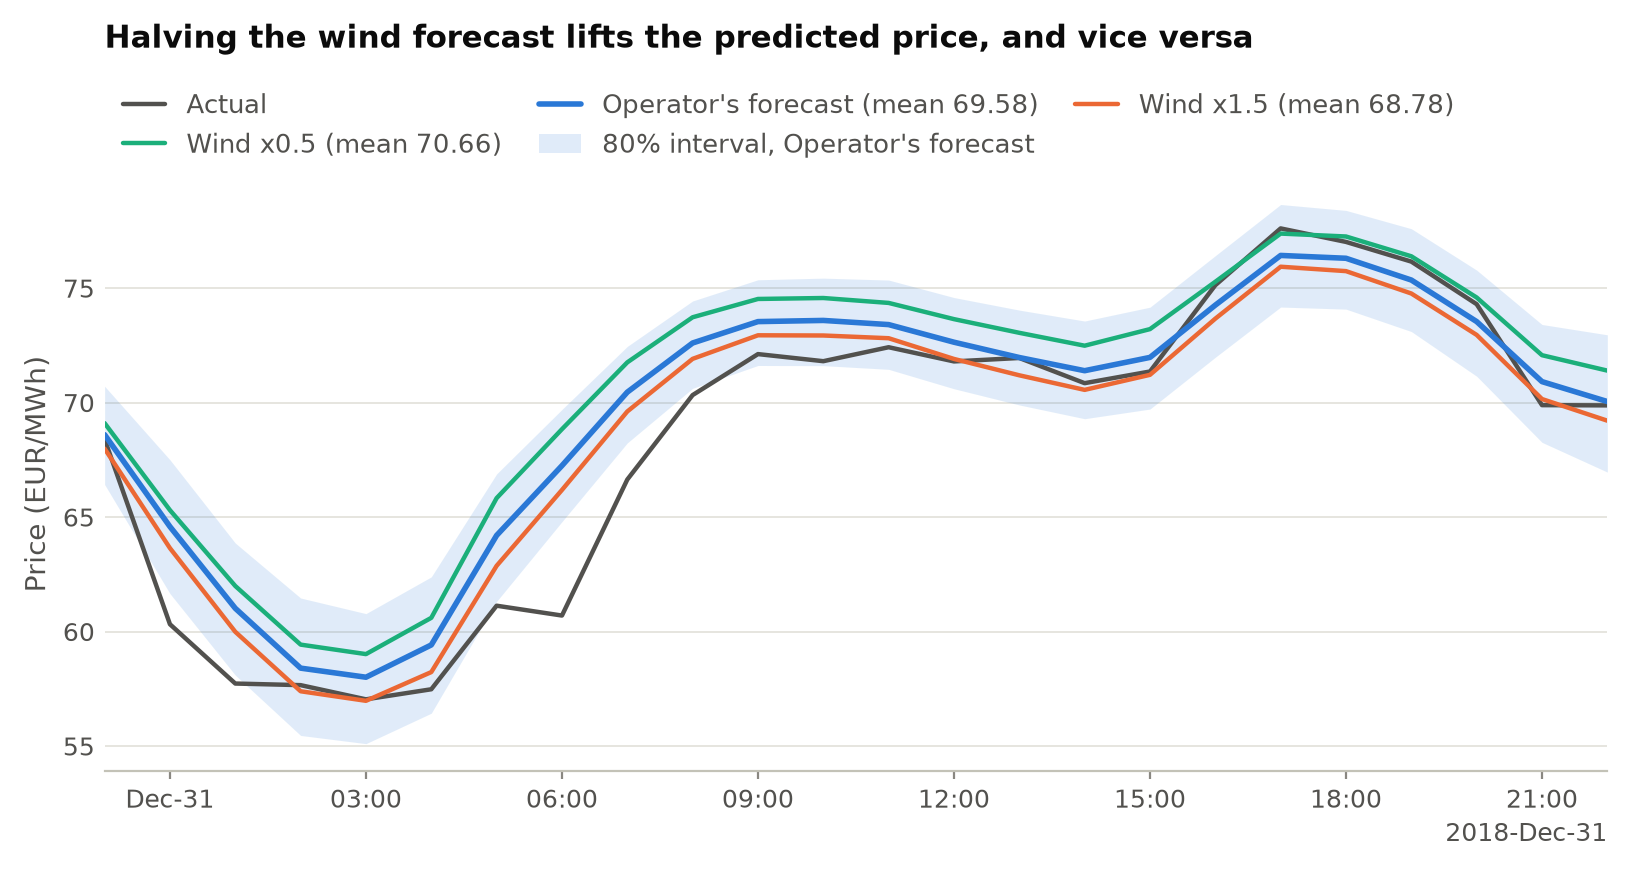

In [15]:
what_if = load_results("06_what_if", PATHS)
# One panel: the three medians differ by about 1 EUR/MWh, which separate panels would hide.
ax = plot_what_if(
    what_if,
    baseline="Operator's forecast",
    actuals=one_actuals,
    target=PRICE,
    title="Halving the wind forecast lifts the predicted price, and vice versa",
    ylabel="Price (EUR/MWh)",
)
(figure_path,) = save_figure(ax.figure, "06_what_if", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 6. Summary, and what none of this proves

- **Ablation is the cheapest answer**, and it asks about one coalition out of sixteen. Where
  it disagrees with the Shapley values beyond what the intervals allow, the disagreement is the
  finding: it means two inputs can stand in for each other. Inside the intervals it is noise.
- **Read the interval before the ranking.** The covariates remove a small share of the loss, so
  their per-window attributions are small numbers with large spreads; the table above says
  which of them are separable from zero at this many windows.
- **Shapley values over a handful of grouped players are affordable** for a zero-shot model, and
  they are exact rather than sampled. Grouping is what makes them possible: four players, sixteen
  coalitions.
- **The same machinery explains the past**, segment by segment, and occlusion gives the shape at
  finer resolution for the price of one forecast per position.
- **What-ifs answer the planner's question** and are checkable against domain knowledge, which
  attribution numbers are not.

What none of it establishes is mechanism. These are statements about the model's *inputs*, not
about electricity markets: if two covariates are correlated, attribution will split their credit
in a way that reflects the model, not the physics. And the group attention weights are not in this
notebook on purpose; reading them as explanation is the step the literature warns
against.

**Next:** article 4 and [`07_finetune_lora`](07_finetune_lora.ipynb): when adapting the weights
beats feeding better inputs.